# Supplemental Figure 3, Panel C

Comparing log2FC accessibility due to BAFinh between GROcap+ (putative active) and GROcap- (putative primed) enhancers, both over timecourse and dosage series of BAFinh

*Output: PanelC_lineplot_GROcap_median_IQR.pdf*

# Setup

In [1]:
library(tidyverse)
library(here)
library(GenomicRanges)
library(patchwork)
library(VennDiagram)
here::i_am("figures/SuppFig3/PanelC/PanelC.ipynb")
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The followi

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] VennDiagram_1.8.2    futile.logger_1.4.3  patchwork_1.3.0     
 [4] GenomicRanges_1.50.2 GenomeInfoDb_1.34.9  IRanges_2.32.0      
 [7] S4Vectors_0.36.2     BiocGenerics_0.44.0  here_1.0.2          
[10] lubridate_1.9.4      forcats_1.0.0        stringr_1.5.1      

# read cRE annotations

In [133]:
# load cRE annotations
cRE_annot <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot.tsv"
cre <- read_tsv(cRE_annot, show_col_types = FALSE)

# make GRanges object
cre_gr <- makeGRangesFromDataFrame(
  cre,
  seqnames.field = "seqnames",
  start.field = "start",
  end.field = "end",
  keep.extra.columns = TRUE
)

# load GROcap bidirectional peaks 
GROcap_bidir <- read.delim(
    here("inputs","eRNA_definition","GROcap","ENCFF187MUG.bed.gz"),
    sep='\t', header=F)

# ake GRanges from GROcap peaks
GROcap_bidir_GR <- GRanges(seqnames=GROcap_bidir$V1, ranges=IRanges(start=GROcap_bidir$V2, end=GROcap_bidir$V3))
ol <- findOverlaps(cre_gr, GROcap_bidir_GR)

#annotate GROcap with ChIP-based cRE annotations
GROcap_bidir_GR$type <- NA
GROcap_bidir_GR$type[subjectHits(ol)] <- cre_gr$type[queryHits(ol)]

#GROcap peaks predominantly consist of promoters and active enhancers, as expected
GROcap_bidir_GR %>% data.frame() %>% group_by(type) %>% summarize(n())

Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': chrY
  - in 'y': chr17_GL000205v2_random, chrEBV, chrM, chrUn_GL000219v1
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this warning).”


type,n()
<chr>,<int>
CTCF_only,247
active_enh,6483
other_TSS,1101
other_nonTSS,1084
poised_enh,410
poised_enh_H3K27me3,9
prom,20836
NA,2487


# generate plots

Rows: 111721 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): seqnames, type, change
dbl (8): start, end, ID, logFC, logCPM, F, PValue, FDR
lgl (2): TSS, BAFdep

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 111721 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): seqnames, type, change
dbl (8): start, end, ID, logFC, logCPM, F, PValue, FDR
lgl (2): TSS, BAFdep

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 111721 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): seqnames, type, change
dbl (8): start, end, ID, logFC, logCPM, F, PValue, FDR
lgl (2): TSS, BAFdep


,GROcap,lfc_0.5,lfc_1,lfc_2,lfc_6,lfc_24
,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,FALSE,-2.0675200,-2.0942220,-1.9946463,-1.6829493,-2.4629957
2,FALSE,-1.5156915,-1.6153026,-2.3613176,-1.7247293,-2.1203866
3,FALSE,-2.1586063,-2.4764909,-2.5332412,-2.3619105,-3.5859102
4,FALSE,-0.1071303,0.1177825,0.3409397,0.2061855,0.2440980
5,FALSE,-0.7588326,-0.7352591,-0.8834049,-0.6306781,-0.8704468
6,FALSE,0.1823515,-0.1105341,-0.3085995,-0.5370326,-0.2603611


name,w_pvalue,p_adj
<chr>,<dbl>,<dbl>
lfc_0.5,0.000000e+00,0.000000e+00
lfc_1,4.856614e-259,2.428307e-258
lfc_2,6.322059e-182,3.161030e-181
lfc_24,3.549796e-145,1.774898e-144
lfc_6,1.389884e-160,6.949421e-160


`summarise()` has grouped output by 'GROcap'. You can override using the
`.groups` argument.


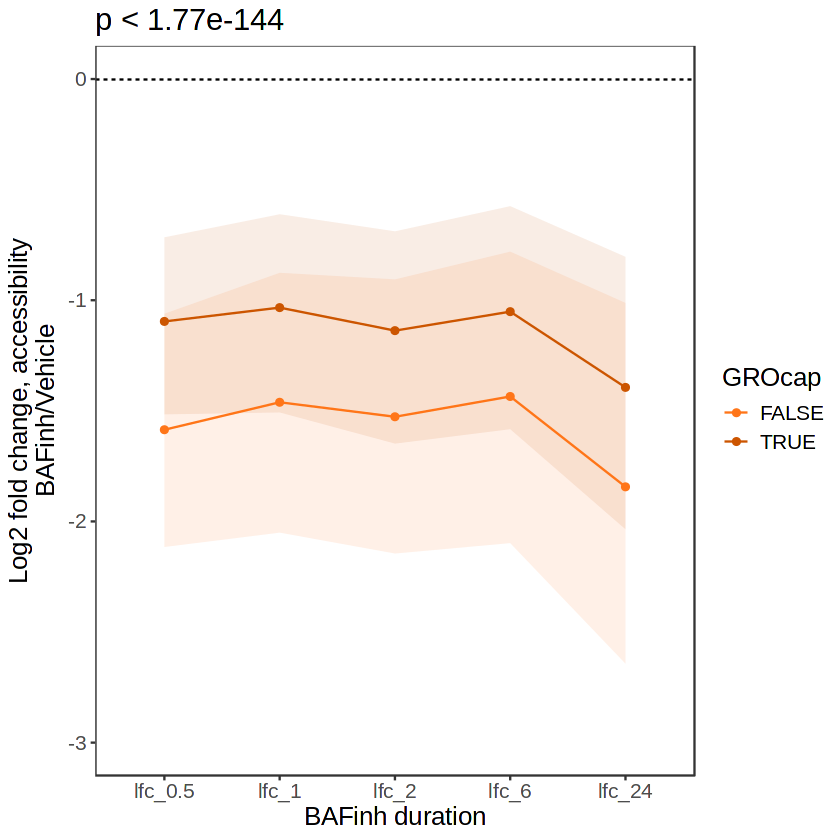

In [171]:
# load differential accessibility results from BAFinhtimecourse
dar_0.5 <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/time_0.5h_DARs.tsv") %>% arrange(seqnames, start)
dar_1 <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/time_1h_DARs.tsv") %>% arrange(seqnames, start)
dar_2 <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/time_2h_DARs.tsv") %>% arrange(seqnames, start)
dar_6 <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/time_6h_DARs.tsv") %>% arrange(seqnames, start)
dar_24 <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/time_24h_DARs.tsv") %>% arrange(seqnames, start)

# aggregate log2FCs
timecourse_lfc <- cbind(cre, lfc_0.5=dar_0.5$logFC, lfc_1=dar_1$logFC, lfc_2=dar_2$logFC, lfc_6=dar_6$logFC, lfc_24=dar_24$logFC) %>%
    mutate(GROcap=countOverlaps(cre_gr, GROcap_bidir_GR) > 0) %>% filter(type %in% c("active_enh", "poised_enh")) %>% # filter for enhancers (H3K4me1+, TSS-distal)
    select(GROcap, lfc_0.5, lfc_1, lfc_2,lfc_6,lfc_24)

# Stats - run wilcoxon rank sum test on GROcap+ vs GROcap- enhancers
pvals_time <- timecourse_lfc %>%
    pivot_longer(!GROcap) %>%
    group_by(name) %>%
        summarize(
        w_pvalue = wilcox.test(value ~ GROcap)$p.value
  )
pvals_time$p_adj <- p.adjust(pvals_time$w_pvalue, method = "bonferroni") #adjust p-vals for multiple testing
pval_time <- max(pvals_time$p_adj) # only report maximum (ie least significant) pval
pvals_time

#generate plot
time_plot <- timecourse_lfc %>%
    pivot_longer(!GROcap) %>%
    group_by(GROcap,name) %>%
    summarize(med=median(value), p25=quantile(value,.25), p75=quantile(value,.75), se=sd(value)/sqrt(length(value))) %>%
    ggplot(aes(x=factor(name, levels=c("lfc_0.5", "lfc_1","lfc_2","lfc_6","lfc_24")), y=med, group=GROcap, color=GROcap, fill=GROcap)) +
    ylim(-3,0) +
    geom_hline(yintercept=0, linetype=2) + 
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)) + 
    geom_ribbon(aes(ymin=p25,ymax=p75), alpha=.1, linewidth=NA) +
    geom_line() +
    geom_point(aes(group=GROcap)) +
    scale_color_manual(values=c("#ff7518", "#cc5500")) +
    scale_fill_manual(values=c("#ff7518", "#cc5500")) +
    ggtitle(paste0("p < ", format(pval_time, digits=3))) +
    ylab("Log2 fold change, accessibility\nBAFinh/Vehicle") + 
    xlab("BAFinh duration") 
time_plot

Rows: 111721 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): seqnames, type, change
dbl (8): start, end, ID, logFC, logCPM, F, PValue, FDR
lgl (2): TSS, BAFdep

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 111721 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): seqnames, type, change
dbl (8): start, end, ID, logFC, logCPM, F, PValue, FDR
lgl (2): TSS, BAFdep

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 111721 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): seqnames, type, change
dbl (8): start, end, ID, logFC, logCPM, F, PValue, FDR
lgl (2): TSS, BAFdep


,GROcap,lfc_10n,lfc_100n,lfc_1u,lfc_10u
,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>
1,FALSE,-0.95919273,-2.29151981,-1.8558102,-1.6829493
2,FALSE,-0.38093042,-1.45412514,-1.7001267,-1.7247293
3,FALSE,-1.01818857,-2.44518142,-2.5846972,-2.3619105
4,FALSE,-0.04053265,-0.04482576,0.3628413,0.2061855
5,FALSE,-0.89005940,-1.19189586,-0.6777537,-0.6306781
6,FALSE,-0.15557603,-0.50191498,-0.5083728,-0.5370326


name,w_pvalue,p_adj
<chr>,<dbl>,<dbl>
lfc_100n,9.434141e-164,3.773656e-163
lfc_10n,1.534910e-40,6.139639e-40
lfc_10u,1.389884e-160,5.559537e-160
lfc_1u,8.445790e-168,3.378316e-167


`summarise()` has grouped output by 'GROcap'. You can override using the
`.groups` argument.


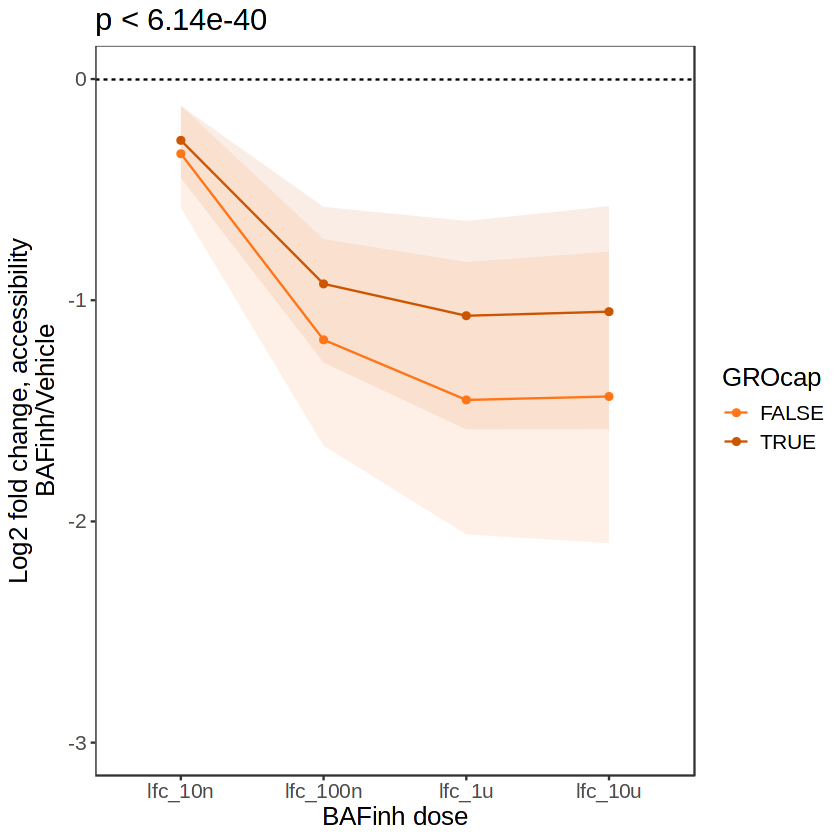

In [172]:
#same as above but for BAFinh dosage series at 6h

dar_10n <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/dose_10nM_DARs.tsv") %>% arrange(seqnames, start)
dar_100n <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/dose_100nM_DARs.tsv") %>% arrange(seqnames, start)
dar_1u <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/dose_1uM_DARs.tsv") %>% arrange(seqnames, start)
dar_10u <- read_tsv("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/dose_10uM_DARs.tsv") %>% arrange(seqnames, start)

dose_lfc <- cbind(cre, lfc_10n=dar_10n$logFC, lfc_100n=dar_100n$logFC, lfc_1u=dar_1u$logFC, lfc_10u=dar_10u$logFC) %>%
    mutate(GROcap=countOverlaps(cre_gr, GROcap_bidir_GR) > 0) %>% filter(type %in% c("active_enh", "poised_enh")) %>% 
    select(GROcap, lfc_10n, lfc_100n, lfc_1u, lfc_10u)

# Stats
pvals_dose <- dose_lfc %>%
    pivot_longer(!GROcap) %>%
    group_by(name) %>%
        summarize(
        w_pvalue = wilcox.test(value ~ GROcap)$p.value
  )
pvals_dose$p_adj <- p.adjust(pvals_dose$w_pvalue, method = "bonferroni")
pval_dose <- max(pvals_dose$p_adj)
pvals_dose

dose_plot <- dose_lfc %>%
    pivot_longer(!GROcap) %>%
    group_by(GROcap,name) %>%
    summarize(med=median(value), p25=quantile(value,.25), p75=quantile(value,.75), se=sd(value)/sqrt(length(value))) %>%
    ggplot(aes(x=factor(name, levels=c("lfc_10n", "lfc_100n","lfc_1u","lfc_10u")), y=med, group=GROcap, color=GROcap, fill=GROcap)) +
    ylim(-3,0) +
    geom_hline(yintercept=0, linetype=2) + 
    theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)) + 
    geom_ribbon(aes(ymin=p25,ymax=p75), alpha=.1, linewidth=NA) +
    geom_line() +
    geom_point(aes(group=GROcap)) +
    scale_color_manual(values=c("#ff7518", "#cc5500")) +
    scale_fill_manual(values=c("#ff7518", "#cc5500")) +
    ggtitle(paste0("p < ", format(pval_dose, digits=3))) +
    ylab("Log2 fold change, accessibility\nBAFinh/Vehicle") + 
    xlab("BAFinh dose") 
dose_plot

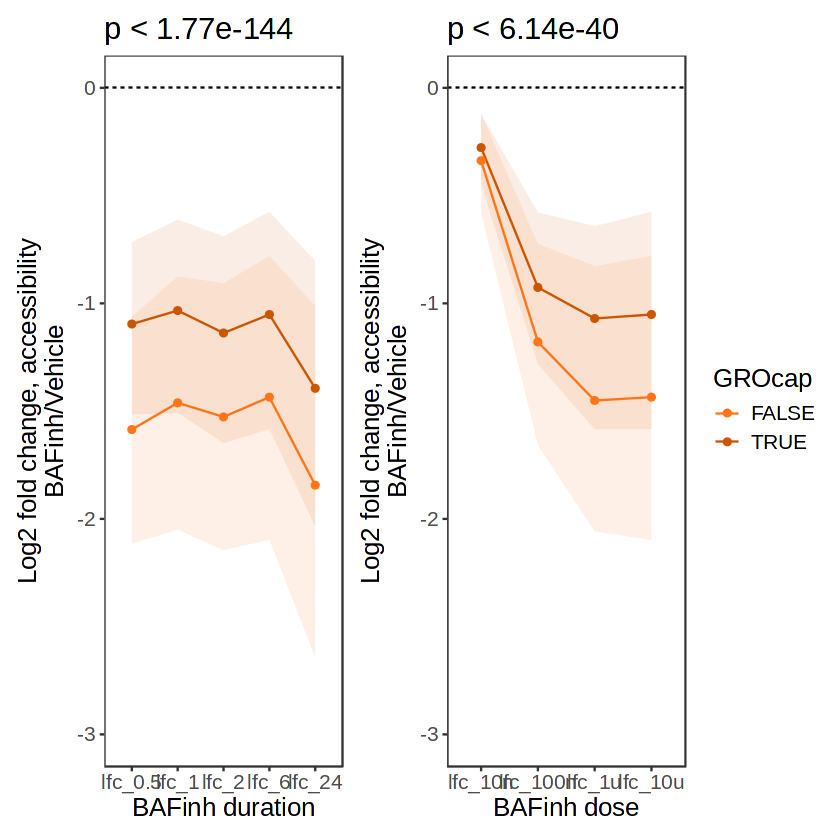

In [175]:
(time_plot | dose_plot) + plot_layout(guides="collect")
ggsave("PanelC_lineplot_GROcap_median_IQR.pdf", height=4, width=9)